# Resultados para la presentación — Reto CAETEC (VMS)

Este notebook **no entrena modelos nuevos**: reutiliza el test cronológico (`data/test_data.npz`) y la
**regresión logística aprobada** (`models/logistic_regresion.keras`) para generar los números y gráficas de la presentación.

| Sección | Para qué sirve |
|---|---|
| 1. Cuándo hay cola (con intervalos de confianza) | Petición del Dr. Aurelio (S11): % de cola por hora con IC |
| 2. La cola en ventanas de 1, 2 y 3 h + duración de episodios | Petición del Dr. Aurelio (S11): bloques de 1–3 h |
| 3. Crecimiento del hato | Escenario "¿qué pasa si hay más vacas?" |
| 4. Pruebas estadísticas sobre el modelo elegido | Bootstrap por día, McNemar, sensibilidad al umbral, calibración |
| 5. Qué variables pesan en el modelo | Odds ratios, separando variables *anticipables* de las del *mismo bloque* |
| 6. Escenarios *what-if* | Probabilidad de cola que predice el modelo bajo condiciones hipotéticas |
| 7. Mensajes clave | Resumen numérico para copiar a las diapositivas |

**Intervalos de confianza:** los bloques de 30 min de un mismo día no son independientes (la cola de un bloque arrastra
al siguiente), así que todos los IC se calculan con **bootstrap por día** (se remuestrean días completos), no con la fórmula binomial.

Las figuras se guardan en `reports/figuras_presentacion/`.

In [1]:
import os
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import importlib.util
import shutil
import sys
from pathlib import Path

# ---------------------------------------------------------------------------
# Configuración (solo si estás en Colab y no se encuentra solo):
RUTA_REPO = ""      # ej. "/content/drive/MyDrive/VMS-prediction"
RUTA_PARQUET = ""   # ej. "/content/drive/MyDrive/CAETEC/Procesado/dataset_final_serie_tiempo.parquet"
ID_PARQUET_DRIVE = "11kL7SO7oeGPu4L3NJ6ZcQAeCAxABsVv5"  # dataset_final_serie_tiempo.parquet en el Drive del equipo
REPO_GIT = "https://github.com/kamimartinez/VMS-prediction.git"
# ---------------------------------------------------------------------------

VERSION_NOTEBOOK = "v4 (22-nov, LR sin Keras)"
print("Versión del notebook:", VERSION_NOTEBOOK)
try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False
if EN_COLAB and not Path("/content/drive/MyDrive").exists():
    from google.colab import drive
    drive.mount("/content/drive")

def _es_repo(p):
    return (p / "notebooks" / "evaluation" / "setup.py").exists() and (p / "models").is_dir()

def buscar_repo():
    candidatos = [Path(RUTA_REPO)] if RUTA_REPO else []
    candidatos += [Path.cwd(), *Path.cwd().parents, Path("/content/VMS-prediction")]
    mydrive = Path("/content/drive/MyDrive")
    if mydrive.exists():
        for patron in ["VMS-prediction", "*/VMS-prediction", "*/*/VMS-prediction", "*/*/*/VMS-prediction"]:
            candidatos += list(mydrive.glob(patron))
    for c in candidatos:
        if _es_repo(c):
            return c.resolve()
    if EN_COLAB:  # último recurso: clonar el repo en la sesión de Colab
        import subprocess
        subprocess.run(["git", "clone", "-q", REPO_GIT, "/content/VMS-prediction"], check=False)
        if _es_repo(Path("/content/VMS-prediction")):
            return Path("/content/VMS-prediction")
    raise FileNotFoundError("No encontré la carpeta VMS-prediction. Escribe su ruta en RUTA_REPO.")

ROOT = buscar_repo()

# Importa el setup.py DEL PROYECTO por ruta (en Colab `import setup` puede cargar otro módulo con el mismo nombre)
_spec = importlib.util.spec_from_file_location("setup_eval", ROOT / "notebooks" / "evaluation" / "setup.py")
S = importlib.util.module_from_spec(_spec)
sys.modules["setup_eval"] = S
_spec.loader.exec_module(S)

# Datos: data/ no viene en git (.gitignore). Si falta, se consigue el parquet y se crea el split
DATA_DIR = ROOT / "data"
DATA_DIR.mkdir(exist_ok=True)
PARQUET = DATA_DIR / "dataset_final_serie_tiempo.parquet"

def _parquet_valido(p):
    try:
        import pyarrow.parquet as pq
        return p.exists() and p.stat().st_size > 1000 and pq.ParquetFile(p).metadata.num_rows > 0
    except Exception:
        return False

def conseguir_parquet():
    # 1) Ruta escrita a mano o archivo visible en Drive montado
    candidatos = [Path(RUTA_PARQUET)] if RUTA_PARQUET else []
    if Path("/content/drive").exists():
        for patron in ["MyDrive/**/dataset_final_serie_tiempo.parquet", "Shareddrives/**/dataset_final_serie_tiempo.parquet"]:
            candidatos += list(Path("/content/drive").glob(patron))[:3]
    for c in candidatos:
        if _parquet_valido(c):
            shutil.copy(c, PARQUET)
            return f"copiado desde {c}"
    if not EN_COLAB:
        return None
    # 2) Descarga por ID con la API de Drive (sirve para archivos de "Compartido conmigo")
    try:
        import io
        from google.colab import auth
        from googleapiclient.discovery import build
        from googleapiclient.http import MediaIoBaseDownload
        auth.authenticate_user()
        buffer = io.BytesIO()
        peticion = build("drive", "v3").files().get_media(fileId=ID_PARQUET_DRIVE, supportsAllDrives=True)
        descarga, terminado = MediaIoBaseDownload(buffer, peticion), False
        while not terminado:
            _, terminado = descarga.next_chunk()
        PARQUET.write_bytes(buffer.getvalue())
        if _parquet_valido(PARQUET):
            return "descargado de Drive por ID"
    except Exception as e:
        print(f"No se pudo descargar de Drive por ID ({type(e).__name__}: {str(e)[:150]})")
    # 3) Último recurso: subirlo desde la computadora
    from google.colab import files
    print("Sube dataset_final_serie_tiempo.parquet (en tu compu está en VMS-prediction/data/):")
    subidos = files.upload()
    for nombre, contenido in subidos.items():
        if nombre.endswith(".parquet"):
            PARQUET.write_bytes(contenido)
            if _parquet_valido(PARQUET):
                return "subido manualmente"
    return None

if not _parquet_valido(PARQUET):
    PARQUET.unlink(missing_ok=True)  # borra restos vacíos o corruptos de intentos anteriores
    resultado = conseguir_parquet()
    if resultado is None:
        raise FileNotFoundError("No se consiguió dataset_final_serie_tiempo.parquet. Ponlo en VMS-prediction/data/ "
                                "o escribe su ruta en RUTA_PARQUET.")
    print(f"Parquet {resultado}")
    (DATA_DIR / "test_data.npz").unlink(missing_ok=True)

if not (DATA_DIR / "test_data.npz").exists():
    _spec_split = importlib.util.spec_from_file_location("create_test_split", ROOT / "notebooks" / "modeling" / "create_test_split.py")
    _split = importlib.util.module_from_spec(_spec_split)
    _spec_split.loader.exec_module(_split)
    _split.create_temporal_split(PARQUET, DATA_DIR / "test_data.npz")
    print("Split 70/15/15 creado en data/test_data.npz")

FIG_DIR = (Path("/content/drive/MyDrive/VMS_figuras_presentacion") if EN_COLAB
           else ROOT / "reports" / "figuras_presentacion")
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"Proyecto: {ROOT}\nFiguras: {FIG_DIR}")

SEED = 42
N_BOOT = 1000

# Estilo: marcas delgadas, ejes discretos, colores fijos por robot
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#9AA5B1", "axes.grid": True, "grid.color": "#E6E6E3",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "lines.linewidth": 2, "legend.frameon": False,
})
AZUL, NARANJA, AQUA, GRIS, TINTA2 = "#2a78d6", "#eb6834", "#1baf7a", "#9AA5B1", "#52514e"
COLOR_ROBOT = {"VMS 1": AZUL, "VMS 2": NARANJA, "VMS 3": AQUA}
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png")
    plt.show()

data = S.load_test_data(project_root=ROOT)

Versión del notebook: v4 (22-nov, LR sin Keras)


Proyecto: /home/claude/vms
Figuras: /home/claude/vms/reports/figuras_presentacion
Datos: 179,850 filas; train=125,894, validación=26,978, test=26,978
Test cronológico: 2025-06-27 15:30:00 -> 2025-12-31 23:30:00
Modelos disponibles: ['logistic_regresion.keras']


In [2]:
# Base común: una fila = un bloque de 30 min de un robot. Cola = pct_posible_cola > 0.5 (misma definición que los modelos)
df = data.full_data.copy()
df["cola"] = (df[data.target] > data.label_threshold).astype(int)
df["fecha"] = df["bloque_tiempo"].dt.normalize()
df["mes"] = df["bloque_tiempo"].dt.to_period("M").dt.to_timestamp()
df["periodo"] = np.where(df["__row_id__"] >= data.validation_end, "Reciente (test)", "Histórico (train + val)")

assert (df["dia_semana"] == df["bloque_tiempo"].dt.dayofweek).mean() > 0.99, "dia_semana no sigue 0 = lunes"

reciente = df[df["periodo"] == "Reciente (test)"]
print(f"Periodo completo: {df['bloque_tiempo'].min():%d/%m/%Y} – {df['bloque_tiempo'].max():%d/%m/%Y}, "
      f"{df['fecha'].nunique():,} días, {len(df):,} bloques")
print(f"Periodo reciente (test): {reciente['bloque_tiempo'].min():%d/%m/%Y} – {reciente['bloque_tiempo'].max():%d/%m/%Y}, "
      f"{reciente['fecha'].nunique():,} días")
print(f"% de bloques con cola — histórico: {df.loc[df.periodo != 'Reciente (test)', 'cola'].mean():.1%} | "
      f"reciente: {reciente['cola'].mean():.1%}")

Periodo completo: 01/08/2022 – 31/12/2025, 1,249 días, 179,850 bloques
Periodo reciente (test): 27/06/2025 – 31/12/2025, 188 días
% de bloques con cola — histórico: 19.6% | reciente: 57.5%


In [3]:
def ic_bootstrap_por_dia(frame, columna_grupo, valor="cola", n_boot=N_BOOT, seed=SEED):
    # Proporción de `valor` por grupo con IC 95 % remuestreando días completos (bootstrap por conglomerado).
    tabla = frame.groupby(["fecha", columna_grupo])[valor].agg(["sum", "count"]).unstack(columna_grupo, fill_value=0)
    sumas, conteos = tabla["sum"].to_numpy(float), tabla["count"].to_numpy(float)
    n_dias = len(tabla)
    rng = np.random.default_rng(seed)
    pesos = rng.multinomial(n_dias, np.full(n_dias, 1 / n_dias), size=n_boot)  # veces que sale cada día
    with np.errstate(invalid="ignore", divide="ignore"):
        estimaciones = (pesos @ sumas) / (pesos @ conteos)
    inf, sup = np.nanpercentile(estimaciones, [2.5, 97.5], axis=0)
    return pd.DataFrame({
        "pct": sumas.sum(0) / conteos.sum(0), "ic_inf": inf, "ic_sup": sup,
        "n_bloques": conteos.sum(0).astype(int),
    }, index=tabla["sum"].columns)

## 1. ¿Cuándo hay cola? (% de bloques con cola, IC 95 %)

Se comparan el **periodo histórico** y el **periodo reciente** (jun–dic 2025, el mismo del test), porque la frecuencia de la cola
cambió mucho entre ambos (ver sección 3). Para hablar de la operación *actual* conviene usar el periodo reciente.

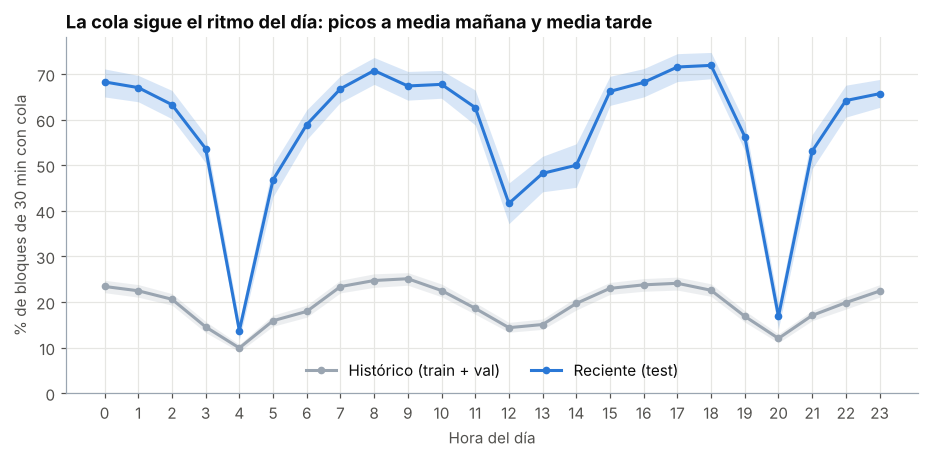

Periodo reciente — horas con más y menos cola


,% cola,IC inf,IC sup,bloques
hora,,,,
18,71.9,69.0,74.7,1128
17,71.5,68.4,74.5,1128
8,70.8,67.7,73.6,1122
0,68.3,65.0,71.1,1122
4,13.7,11.8,15.8,1122
20,16.8,14.1,19.6,1128
12,41.6,37.2,46.1,1122
5,46.8,43.1,50.2,1122


In [4]:
fig, ax = plt.subplots(figsize=(10, 4.2))
por_hora = {}
for nombre, color in [("Histórico (train + val)", GRIS), ("Reciente (test)", AZUL)]:
    r = ic_bootstrap_por_dia(df[df["periodo"] == nombre], "hora")
    por_hora[nombre] = r
    ax.fill_between(r.index, r["ic_inf"] * 100, r["ic_sup"] * 100, color=color, alpha=0.18, linewidth=0)
    ax.plot(r.index, r["pct"] * 100, color=color, marker="o", markersize=4, label=nombre)
ax.set(xlabel="Hora del día", ylabel="% de bloques de 30 min con cola", xticks=range(0, 24), ylim=(0, None))
ax.set_title("La cola sigue el ritmo del día: picos a media mañana y media tarde")
ax.legend(loc="lower center", ncol=2)
guardar(fig, "01_cola_por_hora_ic")

tabla_hora = por_hora["Reciente (test)"].mul([100, 100, 100, 1]).round(1)
tabla_hora.columns = ["% cola", "IC inf", "IC sup", "bloques"]
print("Periodo reciente — horas con más y menos cola")
display(pd.concat([tabla_hora.nlargest(4, "% cola"), tabla_hora.nsmallest(4, "% cola")]))

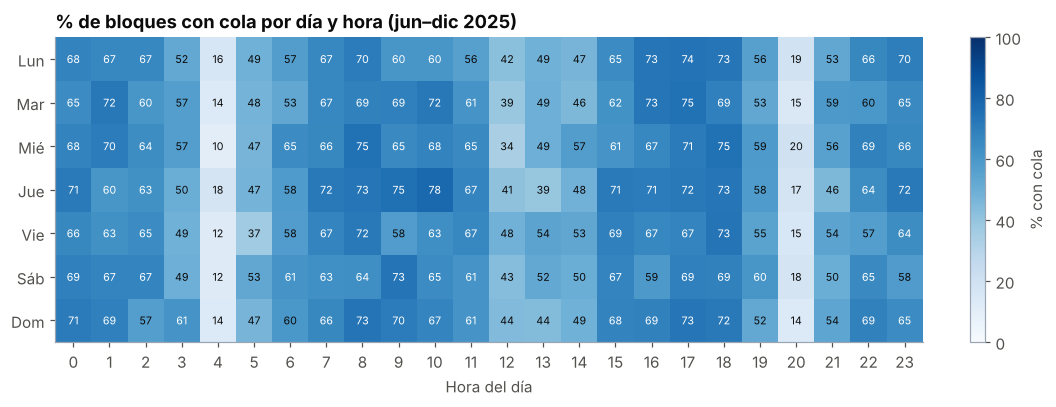

In [5]:
# Heatmap hora × día de la semana (periodo reciente)
mapa = reciente.pivot_table(index="dia_semana", columns="hora", values="cola", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(mapa.values, aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(24)); ax.set_xticklabels(range(24))
ax.set_yticks(range(7)); ax.set_yticklabels(DIAS)
ax.grid(False)
for (i, j), v in np.ndenumerate(mapa.values):
    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 60 else "#0b0b0b")
ax.set_xlabel("Hora del día")
ax.set_title("% de bloques con cola por día y hora (jun–dic 2025)")
fig.colorbar(im, ax=ax, label="% con cola", fraction=0.025)
guardar(fig, "02_heatmap_hora_dia")

% cola  ic_inf  ic_sup
periodo                 robot                        
Histórico (train + val) VMS 1    22.0    21.2    22.9
                        VMS 2    19.2    18.2    20.2
                        VMS 3    17.5    16.6    18.3
Reciente (test)         VMS 1    63.1    61.4    64.7
                        VMS 2    56.7    55.4    58.0
                        VMS 3    52.8    51.4    54.1

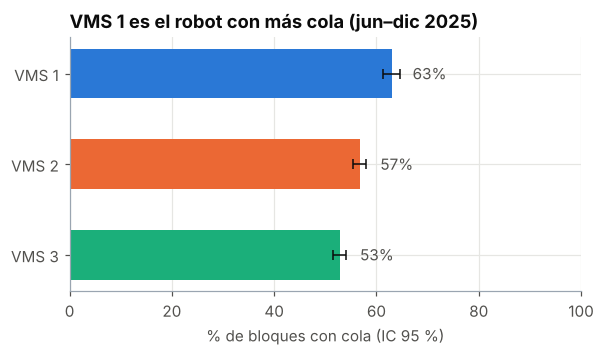

In [6]:
# Por robot, con IC (ambos periodos)
por_robot = pd.concat({
    nombre: ic_bootstrap_por_dia(df[df["periodo"] == nombre], "ms") for nombre in ["Histórico (train + val)", "Reciente (test)"]
}, names=["periodo", "robot"])
display((por_robot[["pct", "ic_inf", "ic_sup"]] * 100).round(1).rename(columns={"pct": "% cola"}))

r = por_robot.loc["Reciente (test)"]
fig, ax = plt.subplots(figsize=(6, 3))
y = np.arange(len(r))
ax.barh(y, r["pct"] * 100, color=[COLOR_ROBOT[m] for m in r.index], height=0.55)
ax.errorbar(r["pct"] * 100, y, xerr=[(r["pct"] - r["ic_inf"]) * 100, (r["ic_sup"] - r["pct"]) * 100],
            fmt="none", ecolor="#0b0b0b", capsize=3, linewidth=1)
for yi, v in zip(y, r["pct"]):
    ax.text(v * 100 + 4, yi, f"{v:.0%}", va="center", color=TINTA2)
ax.set_yticks(y); ax.set_yticklabels(r.index); ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel="% de bloques con cola (IC 95 %)")
ax.set_title("VMS 1 es el robot con más cola (jun–dic 2025)")
guardar(fig, "03_cola_por_robot")

## 2. La cola en ventanas de 1, 2 y 3 horas

Se agrupan los bloques de 30 min de cada robot en ventanas de 1, 2 y 3 h. Una ventana se considera **saturada** si
**al menos la mitad de su tiempo** tuvo cola (misma lógica del umbral de 0.5). Así la cola se lee como "turnos de saturación"
en lugar de pedacitos de 30 min. Periodo reciente.

,ventana,% ventanas saturadas,IC inf,IC sup,ventanas
0,1 h,76.4,75.4,77.4,13488.0
1,2 h,73.8,72.4,75.1,6744.0
2,3 h,74.0,72.4,75.6,4494.0


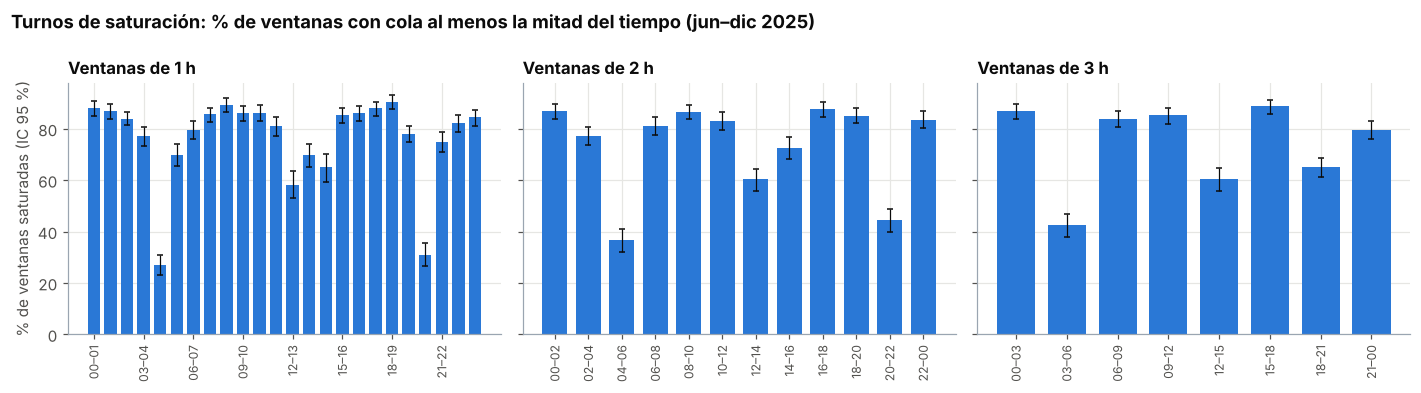

In [7]:
def ventanas(frame, horas):
    out = []
    for robot, g in frame.groupby("ms"):
        v = (g.set_index("bloque_tiempo")["cola"]
               .resample(f"{horas}h", origin="start_day").agg(["mean", "count"]))
        v = v[v["count"] == horas * 2]  # solo ventanas completas
        v["ms"] = robot
        out.append(v)
    v = pd.concat(out).reset_index()
    v["saturada"] = (v["mean"] >= 0.5).astype(int)
    v["fecha"] = v["bloque_tiempo"].dt.normalize()
    v["inicio"] = v["bloque_tiempo"].dt.hour
    return v

resumen_ventanas, perfiles = [], {}
for h in [1, 2, 3]:
    v = ventanas(reciente, h)
    v["todo"] = "todas"
    tot = ic_bootstrap_por_dia(v, "todo", valor="saturada").iloc[0]
    resumen_ventanas.append({"ventana": f"{h} h", "% ventanas saturadas": tot["pct"] * 100,
                             "IC inf": tot["ic_inf"] * 100, "IC sup": tot["ic_sup"] * 100, "ventanas": tot["n_bloques"]})
    perfiles[h] = ic_bootstrap_por_dia(v, "inicio", valor="saturada")
display(pd.DataFrame(resumen_ventanas).round(1))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, h in zip(axes, [1, 2, 3]):
    p = perfiles[h]
    etiquetas = [f"{i:02d}–{(i + h) % 24:02d}" for i in p.index]
    ax.bar(range(len(p)), p["pct"] * 100, color=AZUL, width=0.75)
    ax.errorbar(range(len(p)), p["pct"] * 100,
                yerr=[(p["pct"] - p["ic_inf"]) * 100, (p["ic_sup"] - p["pct"]) * 100],
                fmt="none", ecolor="#0b0b0b", capsize=2, linewidth=0.8)
    paso = {1: 3, 2: 1, 3: 1}[h]
    ax.set_xticks(range(0, len(p), paso)); ax.set_xticklabels(etiquetas[::paso], rotation=90, fontsize=8)
    ax.set_title(f"Ventanas de {h} h", fontsize=11)
axes[0].set_ylabel("% de ventanas saturadas (IC 95 %)")
fig.suptitle("Turnos de saturación: % de ventanas con cola al menos la mitad del tiempo (jun–dic 2025)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
guardar(fig, "04_ventanas_1_2_3h")

Episodios de cola (jun–dic 2025): 5,164
Duración mediana: 1.0 h | media: 1.5 h | p90: 3.0 h | % que duran ≥ 2 h: 29%


,count,mean,std,min,50%,90%,max
ms,,,,,,,
VMS 1,1653.0,1.72,1.54,0.5,1.0,4.0,10.0
VMS 2,1672.0,1.53,1.23,0.5,1.0,3.5,8.0
VMS 3,1839.0,1.29,1.00,0.5,1.0,2.5,7.5


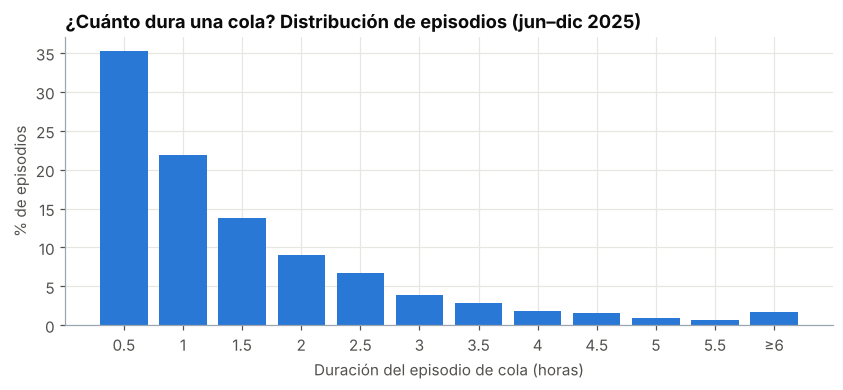

In [8]:
# Duración de los episodios de cola: bloques consecutivos con cola en el mismo robot
def episodios(frame):
    filas = []
    for robot, g in frame.sort_values("bloque_tiempo").groupby("ms"):
        t = g["bloque_tiempo"]
        nuevo_tramo = (t.diff() != pd.Timedelta("30min")) | (g["cola"] != g["cola"].shift())
        tramo = nuevo_tramo.cumsum()
        e = g[g["cola"] == 1].groupby(tramo[g["cola"] == 1]).agg(inicio=("bloque_tiempo", "first"),
                                                                  bloques=("cola", "size"))
        e["ms"] = robot
        filas.append(e)
    e = pd.concat(filas, ignore_index=True)
    e["horas"] = e["bloques"] * 0.5
    return e

ep = episodios(reciente)
print(f"Episodios de cola (jun–dic 2025): {len(ep):,}")
print(f"Duración mediana: {ep['horas'].median():.1f} h | media: {ep['horas'].mean():.1f} h | "
      f"p90: {ep['horas'].quantile(0.9):.1f} h | % que duran ≥ 2 h: {(ep['horas'] >= 2).mean():.0%}")
display(ep.groupby("ms")["horas"].describe(percentiles=[0.5, 0.9]).round(2))

conteo = ep["bloques"].clip(upper=12).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(conteo.index * 0.5, conteo.values / conteo.sum() * 100, width=0.4, color=AZUL)
ax.set_xticks(conteo.index * 0.5)
ax.set_xticklabels([f"{x:g}" if x < 6 else "≥6" for x in conteo.index * 0.5])
ax.set(xlabel="Duración del episodio de cola (horas)", ylabel="% de episodios")
ax.set_title("¿Cuánto dura una cola? Distribución de episodios (jun–dic 2025)")
guardar(fig, "05_duracion_episodios")

## 3. Crecimiento del hato: ¿más vacas = más cola?

Escenario de negocio: si el hato sigue creciendo, ¿cuánto sube la cola? Se usa el promedio mensual de vacas activas
y el % mensual de bloques con cola. Es una relación **descriptiva** (no causal): en el mismo periodo pudieron cambiar otras cosas.

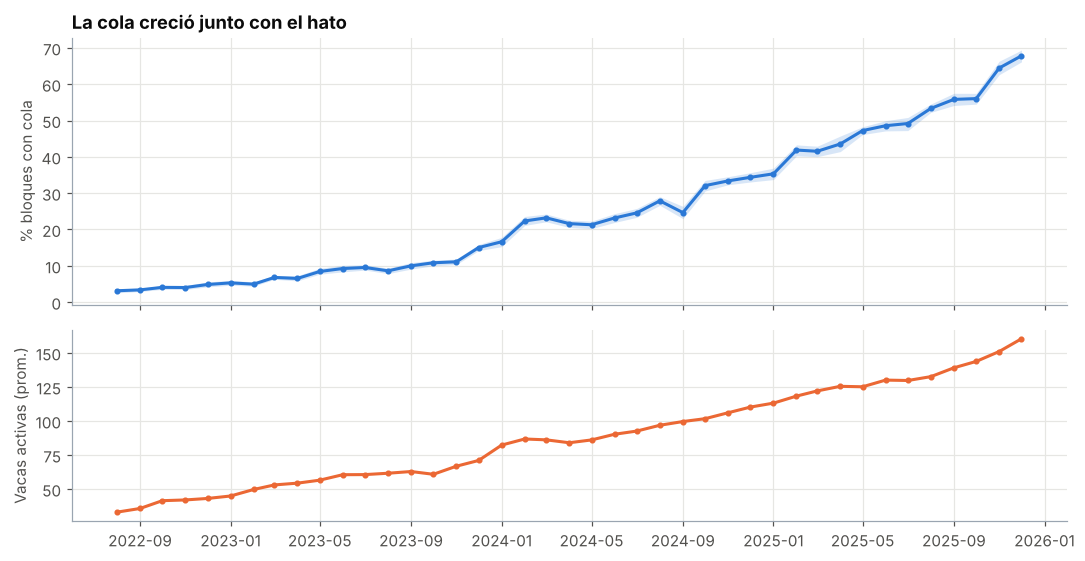

Correlación mensual vacas activas vs % cola: r = 0.99
Por cada +10 vacas activas, la cola sube ≈ 5.3 pp (IC 95 %: 4.8 a 5.8 pp)
  Escenario +10 vacas (162): cola esperada ≈ 64 % (IC 60–68 %)
  Escenario +20 vacas (172): cola esperada ≈ 70 % (IC 65–74 %)
  Escenario +30 vacas (182): cola esperada ≈ 75 % (IC 70–80 %)


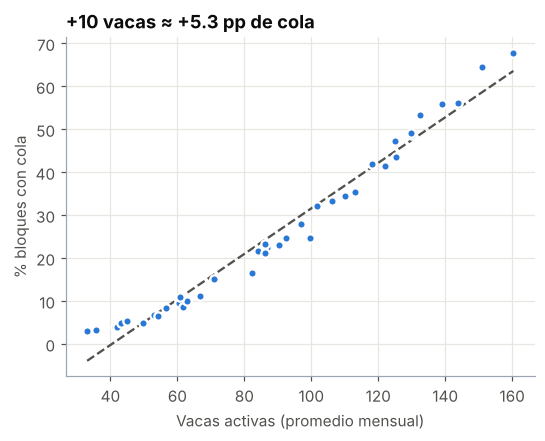

In [9]:
import statsmodels.api as sm

mensual = df.groupby("mes").agg(cola=("cola", "mean"), vacas=("vacas_activas_dia", "mean"), bloques=("cola", "size"))
mensual = mensual[mensual["bloques"] > 500]  # meses con datos suficientes
ic_mes = ic_bootstrap_por_dia(df.assign(m=df["mes"]), "m").loc[mensual.index]

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
a1.fill_between(ic_mes.index, ic_mes["ic_inf"] * 100, ic_mes["ic_sup"] * 100, color=AZUL, alpha=0.18, linewidth=0)
a1.plot(mensual.index, mensual["cola"] * 100, color=AZUL, marker="o", markersize=3)
a1.set(ylabel="% bloques con cola"); a1.set_title("La cola creció junto con el hato")
a2.plot(mensual.index, mensual["vacas"], color=NARANJA, marker="o", markersize=3)
a2.set(ylabel="Vacas activas (prom.)")
fig.tight_layout()
guardar(fig, "06_tendencia_mensual")

X = sm.add_constant(mensual["vacas"])
ols = sm.OLS(mensual["cola"] * 100, X).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
pend, (p_inf, p_sup) = ols.params["vacas"], ols.conf_int().loc["vacas"]
r = np.corrcoef(mensual["vacas"], mensual["cola"])[0, 1]
print(f"Correlación mensual vacas activas vs % cola: r = {r:.2f}")
print(f"Por cada +10 vacas activas, la cola sube ≈ {pend * 10:.1f} pp (IC 95 %: {p_inf * 10:.1f} a {p_sup * 10:.1f} pp)")

actual = mensual["vacas"].iloc[-3:].mean()
for extra in [10, 20, 30]:
    pred = ols.get_prediction(np.array([[1, actual + extra]])).summary_frame(alpha=0.05)
    print(f"  Escenario +{extra} vacas ({actual + extra:.0f}): cola esperada ≈ {pred['mean'].iloc[0]:.0f} % "
          f"(IC {pred['mean_ci_lower'].iloc[0]:.0f}–{pred['mean_ci_upper'].iloc[0]:.0f} %)")

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(mensual["vacas"], mensual["cola"] * 100, s=30, color=AZUL, edgecolor="white", linewidth=1.5, zorder=3)
xs = np.linspace(mensual["vacas"].min(), mensual["vacas"].max(), 50)
ax.plot(xs, ols.params["const"] + pend * xs, color=TINTA2, linewidth=1.5, linestyle="--")
ax.set(xlabel="Vacas activas (promedio mensual)", ylabel="% bloques con cola")
ax.set_title(f"+10 vacas ≈ +{pend * 10:.1f} pp de cola")
guardar(fig, "07_vacas_vs_cola")

## 4. Pruebas estadísticas sobre el modelo elegido (regresión logística)

Preguntas que responde esta sección:
1. **¿Le gana de verdad a las líneas base?** Bootstrap por día de F1, MCC y la diferencia contra "siempre cola" y "bloque anterior".
2. **¿Se equivoca distinto que las líneas base?** Prueba de McNemar (supone independencia entre bloques; el bootstrap es la prueba robusta).
3. **¿Qué tanto depende del umbral 0.2095?** Curva F1 vs umbral.
4. **¿Sus probabilidades son confiables?** Calibración y Brier (necesario para usar las probabilidades en los escenarios).

> **Recalibración:** la LR se entrenó con datos de 2022–2025 en los que la cola era mucho menos frecuente que en el periodo de test,
> por eso sus probabilidades salen bajas (y por eso el umbral óptimo quedó en 0.2095 y no en 0.5). Para los escenarios se usa
> la probabilidad **recalibrada con el periodo de validación** (Platt). El F1, MCC y AUC de esta sección son los del modelo original aprobado.

In [10]:
# Reconstrucción del preprocesamiento de la LR (idéntico a setup._predict_logistic) para poder usarlo en escenarios
def preparar_lr(data):
    target = data.target
    frame = data.full_data.sort_values(["ms", "bloque_tiempo"], kind="stable").reset_index(drop=True)
    grupos = frame.groupby("ms", sort=False)
    continuo = (frame["bloque_tiempo"] - grupos["bloque_tiempo"].shift(1)) == pd.Timedelta("30min")
    lag_cols = [c for c in ["total_ordenios", "duracion_total_min", "pct_ocupacion_robot", "hubo_ordenios"] if c in frame]
    for c in lag_cols:
        frame[f"{c}_anterior"] = grupos[c].shift(1).where(continuo)
    frame["pct_cola_anterior"] = grupos[target].shift(1).where(continuo)
    frame["hora_sin"] = np.sin(2 * np.pi * frame["hora"] / 24)
    frame["hora_cos"] = np.cos(2 * np.pi * frame["hora"] / 24)
    frame["dia_sin"] = np.sin(2 * np.pi * frame["dia_semana"] / 7)
    frame["dia_cos"] = np.cos(2 * np.pi * frame["dia_semana"] / 7)
    frame["cola"] = (frame[target] > data.label_threshold).astype(np.float32)
    frame = frame.sort_values(["bloque_tiempo", "ms"], kind="stable").reset_index(drop=True)
    limpio = frame.drop(columns=lag_cols).dropna(subset=["pct_cola_anterior"]).copy().reset_index(drop=True)
    limpio["ms_original"] = limpio["ms"].astype(str)
    limpio["ms"] = limpio["ms"].astype(str); limpio["temporada"] = limpio["temporada"].astype(str)
    limpio = pd.get_dummies(limpio, columns=["ms", "temporada"], dtype="float32", drop_first=True)
    quitar = [target, "bloque_tiempo", "cola", "produccion_promedio", "sin_etapa", "hora", "dia_semana",
              "vacas_activas_dia", "__row_id__", "ms_original"]
    X = limpio.drop(columns=quitar)
    dummies = [c for c in X.columns if c.startswith(("ms_", "temporada_"))]
    numericas = [c for c in X.select_dtypes(include="number").columns if c not in dummies]
    prep = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value=0)),
                          ("scaler", StandardScaler())]), numericas),
        ("bin", "passthrough", dummies),
    ], remainder="drop", verbose_feature_names_out=False)
    prep.fit(X.iloc[: int(len(X) * 0.70)])
    return limpio, X, prep

limpio, X_lr, prep_lr = preparar_lr(data)
# La LR es una sola capa Dense(1, sigmoide). Se leen sus pesos directo del .keras (es un zip con un .h5)
# para no depender de la versión de Keras instalada (Colab puede traer una más vieja que la que guardó el modelo).
import zipfile, io, h5py
with zipfile.ZipFile(data.models_path / S.MODEL_FILES["Regresión logística"]) as z:
    with h5py.File(io.BytesIO(z.read("model.weights.h5")), "r") as h5:
        W_LR = h5["layers/dense/vars/0"][()].astype(np.float64)   # (25, 1)
        B_LR = h5["layers/dense/vars/1"][()].astype(np.float64)   # (1,)
UMBRAL = data.logistic_decision_threshold

def predecir(X):
    z = prep_lr.transform(X).astype(np.float64) @ W_LR + B_LR
    return (1 / (1 + np.exp(-z))).reshape(-1)

es_test = (limpio["__row_id__"] >= data.validation_end).to_numpy()
test = limpio.loc[es_test, ["__row_id__", "bloque_tiempo", "ms_original", "hora", "dia_semana", "cola",
                            "pct_cola_anterior"]].copy()
X_test = X_lr.loc[es_test].copy()
test["prob"] = predecir(X_test)

# Recalibración (Platt) con el periodo de VALIDACIÓN: el modelo se entrenó con datos donde la cola era mucho menos
# frecuente, así que sus probabilidades salen bajas. Esto NO cambia el orden de las predicciones (ni ROC/PR-AUC);
# solo hace que la probabilidad sea interpretable para los escenarios. El test no se usa para calibrar.
from sklearn.linear_model import LogisticRegression as _Platt
def _logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)
es_val = ((limpio["__row_id__"] >= data.train_end) & (limpio["__row_id__"] < data.validation_end)).to_numpy()
p_val, y_val = predecir(X_lr.loc[es_val]), limpio.loc[es_val, "cola"].astype(int).to_numpy()
platt = _Platt(C=1e6).fit(_logit(p_val), y_val)
def calibrar(p):
    return platt.predict_proba(_logit(np.asarray(p)))[:, 1]
test["prob_cal"] = calibrar(test["prob"])
prev_entrenamiento = limpio.loc[limpio["__row_id__"] < data.train_end, "cola"].mean()
print(f"% de cola — entrenamiento: {prev_entrenamiento:.1%} | validación: {y_val.mean():.1%} | test: {test['cola'].mean():.1%}")

# Verificación: debe reproducir el F1 del reporte de evaluación (0.791)
from sklearn.metrics import f1_score
_f1 = f1_score(test["cola"].astype(int), (test["prob"] >= UMBRAL).astype(int))
assert abs(_f1 - 0.7907) < 0.002, f"F1 {_f1:.4f} no coincide con el reporte (0.791)"
print(f"Verificación OK: F1 = {_f1:.3f} (igual al reporte)")

y = test["cola"].astype(int).to_numpy()
modelos_cmp = {
    "Regresión logística (umbral 0.2095)": (test["prob"] >= UMBRAL).astype(int).to_numpy(),
    "Regresión logística (umbral 0.5)": (test["prob"] >= 0.5).astype(int).to_numpy(),
    "Línea base: siempre cola": np.ones_like(y),
    "Línea base: bloque anterior": (test["pct_cola_anterior"] > data.label_threshold).astype(int).to_numpy(),
}
print(f"Bloques de test: {len(test):,} | prevalencia de cola: {y.mean():.1%} | días: {test['bloque_tiempo'].dt.normalize().nunique()}")

% de cola — entrenamiento: 14.7% | validación: 42.5% | test: 57.5%
Verificación OK: F1 = 0.791 (igual al reporte)
Bloques de test: 26,978 | prevalencia de cola: 57.5% | días: 188


In [11]:
# Bootstrap por día: se suman las matrices de confusión diarias con pesos multinomiales (rápido y exacto)
test["fecha"] = test["bloque_tiempo"].dt.normalize()
dias_idx = test.groupby("fecha").indices
fechas = list(dias_idx)

def conteos_por_dia(pred):
    tp = np.array([((pred[i] == 1) & (y[i] == 1)).sum() for i in dias_idx.values()], float)
    fp = np.array([((pred[i] == 1) & (y[i] == 0)).sum() for i in dias_idx.values()], float)
    fn = np.array([((pred[i] == 0) & (y[i] == 1)).sum() for i in dias_idx.values()], float)
    tn = np.array([((pred[i] == 0) & (y[i] == 0)).sum() for i in dias_idx.values()], float)
    return np.vstack([tp, fp, fn, tn]).T

def f1_mcc(c):
    tp, fp, fn, tn = c[..., 0], c[..., 1], c[..., 2], c[..., 3]
    with np.errstate(invalid="ignore", divide="ignore"):
        f1 = 2 * tp / (2 * tp + fp + fn)
        mcc = (tp * tn - fp * fn) / np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return f1, np.nan_to_num(mcc)

rng = np.random.default_rng(SEED)
pesos = rng.multinomial(len(fechas), np.full(len(fechas), 1 / len(fechas)), size=N_BOOT)
boot = {}
filas = []
for nombre, pred in modelos_cmp.items():
    c = conteos_por_dia(pred)
    f1_p, mcc_p = f1_mcc(c.sum(0))
    f1_b, mcc_b = f1_mcc(pesos @ c)
    boot[nombre] = f1_b
    filas.append({"modelo": nombre, "F1": f1_p, "F1 IC inf": np.percentile(f1_b, 2.5), "F1 IC sup": np.percentile(f1_b, 97.5),
                  "MCC": mcc_p, "MCC IC inf": np.percentile(mcc_b, 2.5), "MCC IC sup": np.percentile(mcc_b, 97.5),
                  "% bloques predichos con cola": pred.mean() * 100})
tabla_modelos = pd.DataFrame(filas).set_index("modelo").round(3)
display(tabla_modelos)

# AUCs (solo para la LR; las líneas base no tienen probabilidad)
aucs = []
for b in range(300):
    idx = np.concatenate([dias_idx[f] for f in rng.choice(fechas, len(fechas))])
    aucs.append((roc_auc_score(y[idx], test["prob"].to_numpy()[idx]), average_precision_score(y[idx], test["prob"].to_numpy()[idx])))
aucs = np.array(aucs)
print(f"ROC-AUC LR: {roc_auc_score(y, test['prob']):.3f} (IC 95 %: {np.percentile(aucs[:, 0], 2.5):.3f}–{np.percentile(aucs[:, 0], 97.5):.3f})")
print(f"PR-AUC  LR: {average_precision_score(y, test['prob']):.3f} (IC 95 %: {np.percentile(aucs[:, 1], 2.5):.3f}–{np.percentile(aucs[:, 1], 97.5):.3f}) "
      f"| PR-AUC de un modelo sin información = prevalencia = {y.mean():.3f}")

print("\nDiferencia de F1: Regresión logística (0.2095) − línea base")
lr_b = boot["Regresión logística (umbral 0.2095)"]
for base in ["Línea base: siempre cola", "Línea base: bloque anterior"]:
    d = lr_b - boot[base]
    print(f"  vs {base.split(': ')[1]:<16}: {d.mean():+.3f} (IC 95 %: {np.percentile(d, 2.5):+.3f} a {np.percentile(d, 97.5):+.3f}) "
          f"| % de remuestreos en que gana la LR: {(d > 0).mean():.1%}")

,F1,F1 IC inf,F1 IC sup,MCC,MCC IC inf,MCC IC sup,% bloques predichos con cola
modelo,,,,,,,
Regresión logística (umbral 0.2095),0.791,0.782,0.799,0.425,0.413,0.437,78.416
Regresión logística (umbral 0.5),0.215,0.201,0.227,0.159,0.148,0.169,8.518
Línea base: siempre cola,0.730,0.721,0.739,0.000,0.000,0.000,100.000
Línea base: bloque anterior,0.667,0.655,0.680,0.217,0.201,0.233,57.536


ROC-AUC LR: 0.762 (IC 95 %: 0.754–0.769)
PR-AUC  LR: 0.771 (IC 95 %: 0.760–0.784) | PR-AUC de un modelo sin información = prevalencia = 0.575

Diferencia de F1: Regresión logística (0.2095) − línea base
  vs siempre cola    : +0.060 (IC 95 %: +0.057 a +0.064) | % de remuestreos en que gana la LR: 100.0%
  vs bloque anterior : +0.123 (IC 95 %: +0.116 a +0.131) | % de remuestreos en que gana la LR: 100.0%


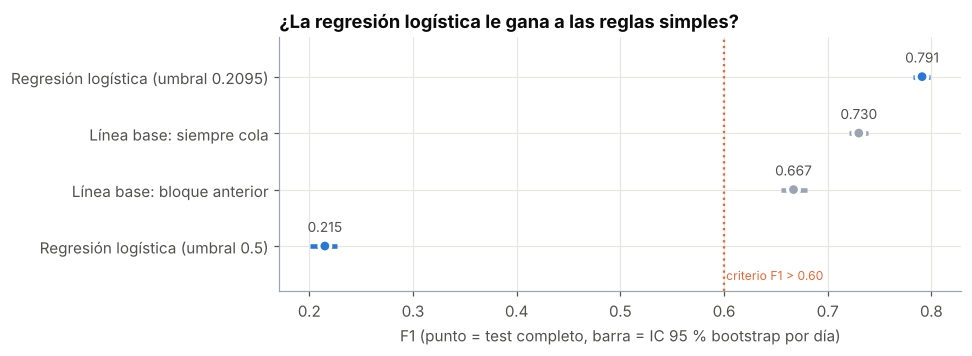

In [12]:
# Gráfica: F1 con IC por modelo + línea de "siempre cola"
t = tabla_modelos.sort_values("F1")
fig, ax = plt.subplots(figsize=(8, 3))
yy = np.arange(len(t))
colores = [AZUL if "Regresión" in n else GRIS for n in t.index]
ax.hlines(yy, t["F1 IC inf"], t["F1 IC sup"], color=colores, linewidth=3)
ax.scatter(t["F1"], yy, color=colores, s=60, zorder=3, edgecolor="white", linewidth=2)
for yi, v in zip(yy, t["F1"]):
    ax.text(v, yi + 0.25, f"{v:.3f}", ha="center", fontsize=9, color=TINTA2)
ax.axvline(0.60, color=NARANJA, linestyle=":", linewidth=1.5)
ax.text(0.602, -0.6, "criterio F1 > 0.60", color=NARANJA, fontsize=8)
ax.set_yticks(yy); ax.set_yticklabels(t.index)
ax.set(xlabel="F1 (punto = test completo, barra = IC 95 % bootstrap por día)", ylim=(-0.8, len(t) - 0.3))
ax.set_title("¿La regresión logística le gana a las reglas simples?")
guardar(fig, "08_f1_ic_modelos")

In [13]:
# McNemar: ¿la LR acierta en bloques distintos que la línea base?
pred_lr = modelos_cmp["Regresión logística (umbral 0.2095)"]
for base in ["Línea base: siempre cola", "Línea base: bloque anterior"]:
    ok_lr, ok_b = pred_lr == y, modelos_cmp[base] == y
    b, c = int((ok_lr & ~ok_b).sum()), int((~ok_lr & ok_b).sum())
    p = binomtest(b, b + c, 0.5).pvalue if b + c else 1.0
    print(f"LR vs {base.split(': ')[1]:<16}: LR acierta y base falla = {b:,} | base acierta y LR falla = {c:,} | p (McNemar exacta) = {p:.2e}")
print("Nota: McNemar supone bloques independientes; el bootstrap por día de arriba es la evidencia robusta.")

LR vs siempre cola    : LR acierta y base falla = 4,802 | base acierta y LR falla = 1,021 | p (McNemar exacta) = 0.00e+00
LR vs bloque anterior : LR acierta y base falla = 6,387 | base acierta y LR falla = 3,738 | p (McNemar exacta) = 2.17e-154
Nota: McNemar supone bloques independientes; el bootstrap por día de arriba es la evidencia robusta.


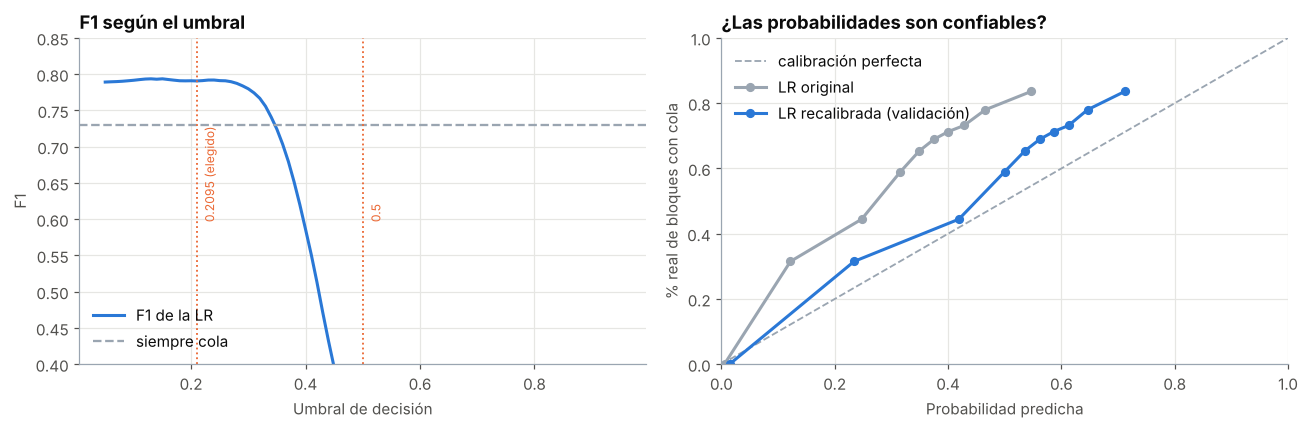

% de bloques que la LR marca como cola con umbral 0.2095: 78.4% (real: 57.5%)
Probabilidad media predicha — original: 32.6% | recalibrada: 48.2% | real: 57.5%
Brier — original: 0.255 | recalibrada: 0.194 | predecir siempre la prevalencia real del test: 0.244
  (la referencia usa la prevalencia del propio test, que el modelo no conoce: es una comparación exigente)


In [14]:
# Sensibilidad al umbral y calibración
umbrales = np.linspace(0.05, 0.95, 91)
prob = test["prob"].to_numpy()
f1_u = [f1_mcc(np.array([((prob >= u) & (y == 1)).sum(), ((prob >= u) & (y == 0)).sum(),
                         ((prob < u) & (y == 1)).sum(), ((prob < u) & (y == 0)).sum()], float))[0] for u in umbrales]
pct_pred = [(prob >= u).mean() * 100 for u in umbrales]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(umbrales, f1_u, color=AZUL, label="F1 de la LR")
a1.axhline(tabla_modelos.loc["Línea base: siempre cola", "F1"], color=GRIS, linestyle="--", linewidth=1.5, label="siempre cola")
for u, txt in [(UMBRAL, "0.2095 (elegido)"), (0.5, "0.5")]:
    a1.axvline(u, color=NARANJA, linestyle=":", linewidth=1.2)
    a1.text(u + 0.01, 0.60, txt, color=NARANJA, fontsize=8, rotation=90)
a1.set(xlabel="Umbral de decisión", ylabel="F1", ylim=(0.4, 0.85))
a1.set_title("F1 según el umbral")
a1.legend(loc="lower left")

frac_pos, prob_media = calibration_curve(y, prob, n_bins=10, strategy="quantile")
a2.plot([0, 1], [0, 1], color=GRIS, linestyle="--", linewidth=1.2, label="calibración perfecta")
a2.plot(prob_media, frac_pos, color=GRIS, marker="o", markersize=5, label="LR original")
frac_c, prob_c = calibration_curve(y, test["prob_cal"], n_bins=10, strategy="quantile")
a2.plot(prob_c, frac_c, color=AZUL, marker="o", markersize=5, label="LR recalibrada (validación)")
a2.set(xlabel="Probabilidad predicha", ylabel="% real de bloques con cola", xlim=(0, 1), ylim=(0, 1))
a2.set_title("¿Las probabilidades son confiables?")
a2.legend(loc="upper left")
fig.tight_layout()
guardar(fig, "09_umbral_y_calibracion")

brier = brier_score_loss(y, prob)
brier_cal = brier_score_loss(y, test["prob_cal"])
brier_ref = brier_score_loss(y, np.full_like(prob, y.mean()))
print(f"% de bloques que la LR marca como cola con umbral 0.2095: {(prob >= UMBRAL).mean():.1%} (real: {y.mean():.1%})")
print(f"Probabilidad media predicha — original: {prob.mean():.1%} | recalibrada: {test['prob_cal'].mean():.1%} | real: {y.mean():.1%}")
print(f"Brier — original: {brier:.3f} | recalibrada: {brier_cal:.3f} | predecir siempre la prevalencia real del test: {brier_ref:.3f}")
print("  (la referencia usa la prevalencia del propio test, que el modelo no conoce: es una comparación exigente)")

## 5. ¿Qué variables pesan en el modelo?

La LR es una capa densa con activación sigmoide sobre variables estandarizadas, así que sus pesos son log-odds:
**OR por 1 DE** = cuánto se multiplican los momios de cola al subir la variable una desviación estándar (comparable entre variables).

Se separan dos tipos de variables, porque cambian lo que se puede decir:
- **Anticipables**: se conocen *antes* de que empiece el bloque (hora, día, robot, temporada, lo que pasó en el bloque anterior, tiempo desde la alimentación). Sirven para **predecir**.
- **Del mismo bloque**: se miden *durante* el bloque (patadas, ordeños en otros robots, composición de las vacas ordeñadas). Sirven para **explicar**, no para anticipar.

> Ojo: las `pct_fresca/alta/baja/extendida` suman 1 cuando hubo ordeños y 0 cuando no, así que en parte capturan "hubo ordeños en el bloque" más que la etapa de lactancia.

,variable,peso,tipo,OR por 1 DE / dummy,OR unidad natural,unidad
0,pct_fresca,1.564,Mismo bloque (explica),4.779,1.508,+10 pp
1,pct_alta,1.439,Mismo bloque (explica),4.215,1.536,+10 pp
2,pct_baja,1.197,Mismo bloque (explica),3.312,1.502,+10 pp
3,pct_extendida,0.784,Mismo bloque (explica),2.190,1.519,+10 pp
4,ordenios_con_lavado,-0.430,Mismo bloque (explica),0.650,NaN,
5,temporada_primavera,-0.236,Anticipable (predice),0.789,NaN,
6,ms_VMS 3,-0.235,Anticipable (predice),0.791,NaN,
7,patadas_totales,0.158,Mismo bloque (explica),1.171,1.307,+1 patada
8,ordenios_otros_robots,0.156,Mismo bloque (explica),1.168,1.097,+1 ordeño
9,ms_VMS 2,-0.134,Anticipable (predice),0.874,NaN,


Nota: los dummies ms_VMS 2/3 y temporada_* se comparan contra VMS 1 y la temporada base (drop_first).


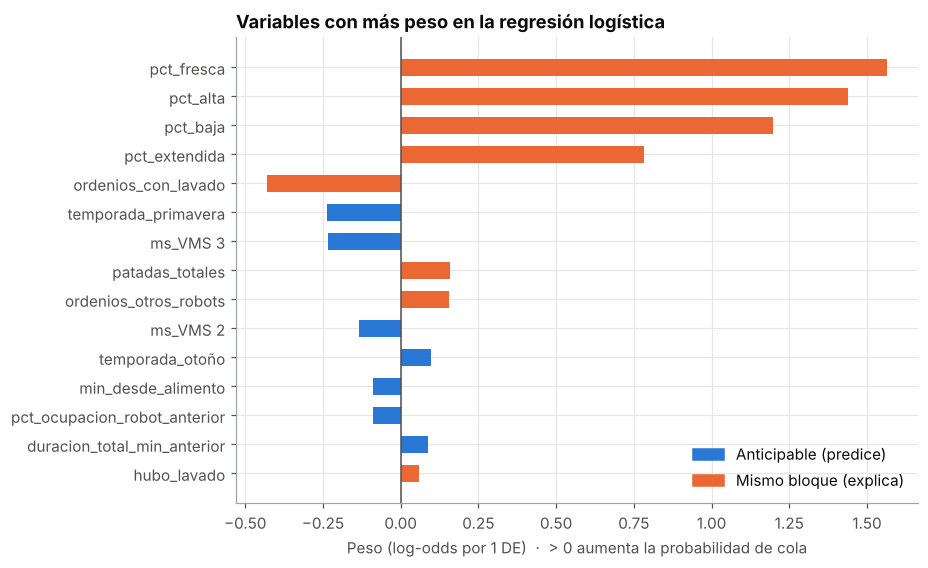

In [15]:
W, b0 = W_LR, B_LR
nombres = prep_lr.get_feature_names_out()
escala = pd.Series(prep_lr.named_transformers_["num"].named_steps["scaler"].scale_,
                   index=prep_lr.transformers_[0][2])

MISMO_BLOQUE = {"patadas_totales", "desviaciones_leche_totales", "ordenios_con_lavado", "hubo_lavado",
                "ordenios_otros_robots", "pct_primer_parto", "pct_fresca", "pct_alta", "pct_baja", "pct_extendida"}
UNIDAD = {"pct_cola_anterior": (0.10, "+10 pp"), "pct_primer_parto": (0.10, "+10 pp"), "pct_fresca": (0.10, "+10 pp"),
          "pct_alta": (0.10, "+10 pp"), "pct_baja": (0.10, "+10 pp"), "pct_extendida": (0.10, "+10 pp"),
          "pct_ocupacion_robot_anterior": (0.10, "+10 pp"), "min_desde_alimento": (60, "+1 h"),
          "ordenios_otros_robots": (1, "+1 ordeño"), "patadas_totales": (1, "+1 patada"),
          "total_ordenios_anterior": (1, "+1 ordeño"), "duracion_total_min_anterior": (10, "+10 min")}

coef = pd.DataFrame({"variable": nombres, "peso": W.reshape(-1)})
coef["tipo"] = np.where(coef["variable"].isin(MISMO_BLOQUE), "Mismo bloque (explica)", "Anticipable (predice)")
coef["OR por 1 DE / dummy"] = np.exp(coef["peso"])
coef["OR unidad natural"] = [
    np.exp(p / escala[v] * UNIDAD[v][0]) if v in UNIDAD else np.nan for v, p in zip(coef["variable"], coef["peso"])]
coef["unidad"] = [UNIDAD[v][1] if v in UNIDAD else "" for v in coef["variable"]]
coef = coef.reindex(coef["peso"].abs().sort_values(ascending=False).index).reset_index(drop=True)
display(coef.round(3))
print("Nota: los dummies ms_VMS 2/3 y temporada_* se comparan contra VMS 1 y la temporada base (drop_first).")

top = coef.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
colores = [NARANJA if t.startswith("Mismo") else AZUL for t in top["tipo"]]
ax.barh(top["variable"], top["peso"], color=colores, height=0.6)
ax.axvline(0, color=TINTA2, linewidth=1)
ax.set(xlabel="Peso (log-odds por 1 DE)  ·  > 0 aumenta la probabilidad de cola")
ax.set_title("Variables con más peso en la regresión logística")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label="Anticipable (predice)"), Patch(color=NARANJA, label="Mismo bloque (explica)")],
          loc="lower right")
guardar(fig, "10_pesos_lr")

## 6. Escenarios *what-if*

Las probabilidades de esta sección son las **recalibradas** (ver sección 4).

Método (*dependencia parcial*): se toman **todos los bloques reales del periodo reciente**, se cambia solo la condición del escenario
(por ejemplo, "el bloque anterior tuvo cola") y se promedia la probabilidad de cola que da el modelo. Así cada escenario conserva
combinaciones realistas del resto de las variables.

- Escenarios **anticipables** → se pueden usar como alerta temprana.
- Escenarios **del mismo bloque** → describen el fenómeno, no se conocen de antemano.

Primero, una validación visual: ¿el modelo reproduce el patrón diario real?

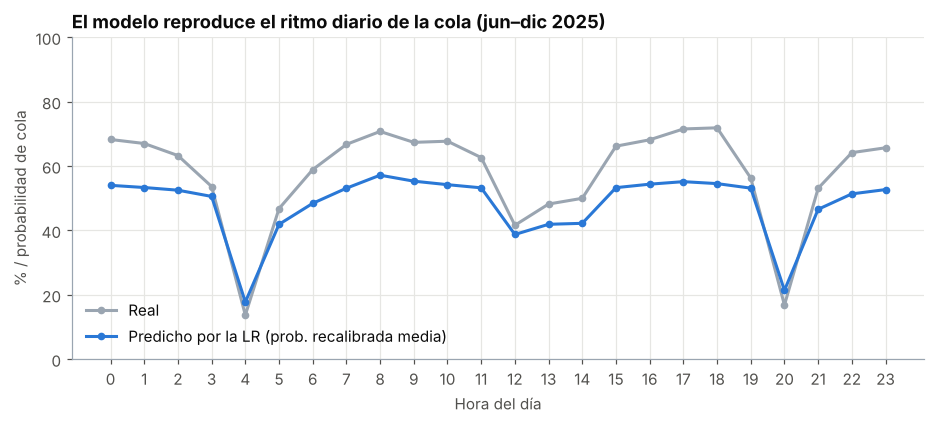

In [16]:
real_h = test.groupby("hora")["cola"].mean() * 100
pred_h = test.groupby("hora")["prob_cal"].mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(real_h.index, real_h, color=GRIS, marker="o", markersize=4, label="Real")
ax.plot(pred_h.index, pred_h, color=AZUL, marker="o", markersize=4, label="Predicho por la LR (prob. recalibrada media)")
ax.set(xlabel="Hora del día", ylabel="% / probabilidad de cola", xticks=range(24), ylim=(0, 100))
ax.set_title("El modelo reproduce el ritmo diario de la cola (jun–dic 2025)")
ax.legend(loc="lower left")
guardar(fig, "11_real_vs_predicho_hora")

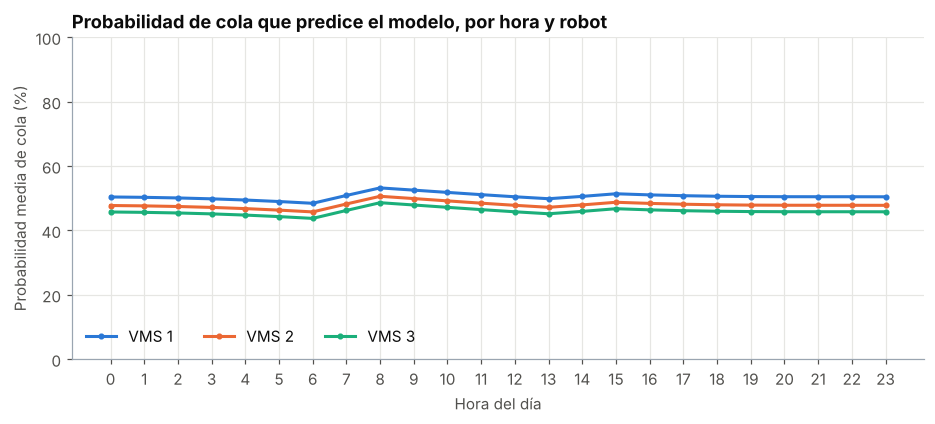

Hora con mayor probabilidad: 8:00 | menor: 6:00


In [17]:
# Mapa hora -> minutos desde la alimentación típicos (la alimentación es a horas fijas)
min_alim_por_hora = df.groupby("hora")["min_desde_alimento"].median()

def poner_hora(X, h):
    X = X.copy()
    X["hora_sin"], X["hora_cos"] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    X["min_desde_alimento"] = min_alim_por_hora[h]
    return X

def poner_robot(X, robot):
    X = X.copy()
    for m in ["VMS 2", "VMS 3"]:
        if f"ms_{m}" in X:
            X[f"ms_{m}"] = float(robot == m)
    return X

def escenario(**cambios):
    X = X_test.copy()
    for col, val in cambios.items():
        if col == "hora":
            X = poner_hora(X, val)
        elif col == "robot":
            X = poner_robot(X, val)
        else:
            X[col] = val(X[col]) if callable(val) else val
    return calibrar(predecir(X)).mean()

# Curva de probabilidad por hora y robot (todo lo demás como en los bloques reales)
curvas = {r: [escenario(hora=h, robot=r) * 100 for h in range(24)] for r in ["VMS 1", "VMS 2", "VMS 3"]}
fig, ax = plt.subplots(figsize=(10, 3.8))
for r, v in curvas.items():
    ax.plot(range(24), v, color=COLOR_ROBOT[r], marker="o", markersize=3, label=r)
ax.set(xlabel="Hora del día", ylabel="Probabilidad media de cola (%)", xticks=range(24), ylim=(0, 100))
ax.set_title("Probabilidad de cola que predice el modelo, por hora y robot")
ax.legend(loc="lower left", ncol=3)
guardar(fig, "12_curva_prob_hora_robot")

curva_media = np.mean(list(curvas.values()), axis=0)
HORA_PICO, HORA_VALLE = int(np.argmax(curva_media)), int(np.argmin(curva_media))
print(f"Hora con mayor probabilidad: {HORA_PICO}:00 | menor: {HORA_VALLE}:00")

Base (bloques reales jun–dic 2025): probabilidad media de cola = 48.2%


,tipo,escenario,prob_cola_%,cambio_vs_base_pp,semáforo
0,Anticipable,El bloque anterior SÍ tuvo cola,49.5,1.3,🟡 medio
1,Anticipable,El bloque anterior NO tuvo cola,46.1,-2.1,🟡 medio
2,Anticipable,Hora pico (8:00),50.8,2.6,🟡 medio
3,Anticipable,Hora valle (6:00),46.0,-2.2,🟡 medio
4,Anticipable,Todo en VMS 1,50.6,2.4,🟡 medio
5,Anticipable,Todo en VMS 3,46.0,-2.2,🟡 medio
6,Anticipable,PEOR CASO: 8:00 + VMS 1 + cola previa,54.5,6.2,🟡 medio
7,Anticipable,MEJOR CASO: 6:00 + VMS 3 + sin cola previa,41.6,-6.6,🟡 medio
8,Mismo bloque,Robots vecinos saturados (7 ordeños),51.6,3.4,🟡 medio
9,Mismo bloque,Robots vecinos tranquilos (1 ordeños),40.5,-7.7,🟡 medio


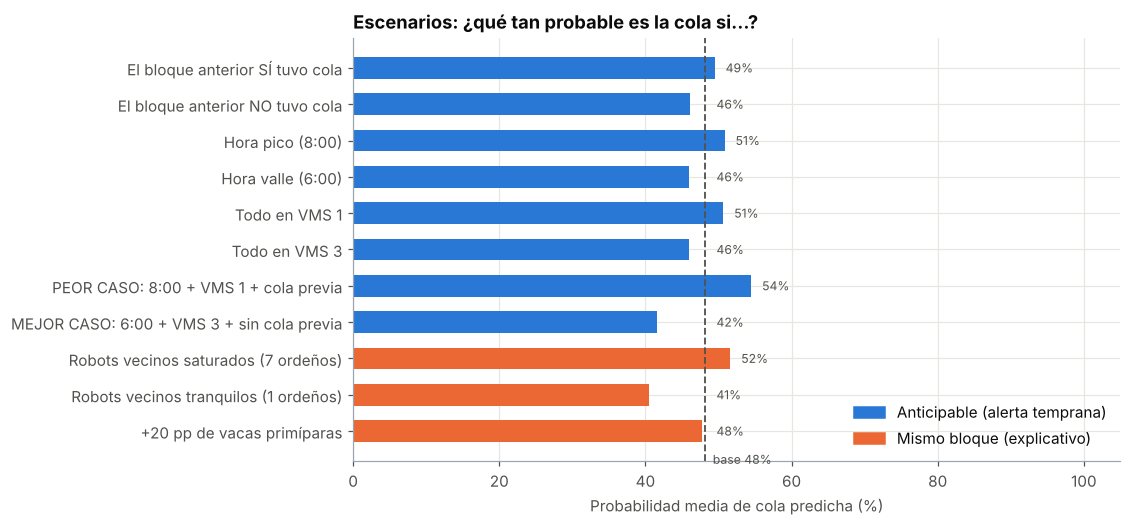

In [18]:
p10, p90 = X_test["ordenios_otros_robots"].quantile([0.1, 0.9])
base = escenario()
escenarios = [
    ("Anticipable", "El bloque anterior SÍ tuvo cola", dict(pct_cola_anterior=1.0)),
    ("Anticipable", "El bloque anterior NO tuvo cola", dict(pct_cola_anterior=0.0)),
    ("Anticipable", f"Hora pico ({HORA_PICO}:00)", dict(hora=HORA_PICO)),
    ("Anticipable", f"Hora valle ({HORA_VALLE}:00)", dict(hora=HORA_VALLE)),
    ("Anticipable", "Todo en VMS 1", dict(robot="VMS 1")),
    ("Anticipable", "Todo en VMS 3", dict(robot="VMS 3")),
    ("Anticipable", f"PEOR CASO: {HORA_PICO}:00 + VMS 1 + cola previa", dict(hora=HORA_PICO, robot="VMS 1", pct_cola_anterior=1.0)),
    ("Anticipable", f"MEJOR CASO: {HORA_VALLE}:00 + VMS 3 + sin cola previa", dict(hora=HORA_VALLE, robot="VMS 3", pct_cola_anterior=0.0)),
    ("Mismo bloque", f"Robots vecinos saturados ({p90:.0f} ordeños)", dict(ordenios_otros_robots=p90)),
    ("Mismo bloque", f"Robots vecinos tranquilos ({p10:.0f} ordeños)", dict(ordenios_otros_robots=p10)),
    ("Mismo bloque", "+20 pp de vacas primíparas", dict(pct_primer_parto=lambda s: (s + 0.2).clip(0, 1))),
]
res = pd.DataFrame([{"tipo": t, "escenario": n, "prob_cola_%": escenario(**c) * 100} for t, n, c in escenarios])
res["cambio_vs_base_pp"] = res["prob_cola_%"] - base * 100
res["semáforo"] = pd.cut(res["prob_cola_%"], [-1, 40, 60, 101], labels=["🟢 bajo", "🟡 medio", "🔴 alto"])
print(f"Base (bloques reales jun–dic 2025): probabilidad media de cola = {base:.1%}")
display(res.round(1))

r = res.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
colores = [AZUL if t == "Anticipable" else NARANJA for t in r["tipo"]]
ax.barh(r["escenario"], r["prob_cola_%"], color=colores, height=0.6)
ax.axvline(base * 100, color=TINTA2, linestyle="--", linewidth=1.2)
ax.text(base * 100 + 1, -0.9, f"base {base:.0%}", color=TINTA2, fontsize=8)
for yi, v in enumerate(r["prob_cola_%"]):
    ax.text(max(v, base * 100) + 1.5, yi, f"{v:.0f}%", va="center", fontsize=8, color=TINTA2)
ax.set(xlim=(0, 105), xlabel="Probabilidad media de cola predicha (%)")
ax.set_title("Escenarios: ¿qué tan probable es la cola si…?")
ax.legend(handles=[Patch(color=AZUL, label="Anticipable (alerta temprana)"), Patch(color=NARANJA, label="Mismo bloque (explicativo)")],
          loc="lower right")
guardar(fig, "13_escenarios")

## 6b. Criterio 2: etapa de lactancia y primíparas (chi²)

Misma metodología que `LogisticRegression2.0.ipynb`: bloques con ordeños y etapa conocida, etapa **dominante** del bloque
(la de mayor proporción) y cola = `pct_posible_cola > 0.5`. Todo el periodo.

Bloques con ordeños y etapa conocida: 123,040 | % con cola: 36.4%
Etapa dominante × cola: chi² = 38.15, gl = 3, p = 2.63e-08, V de Cramér = 0.018
Primíparas × cola:      chi² = 233.11, gl = 1, p = 1.25e-52, V de Cramér = 0.044


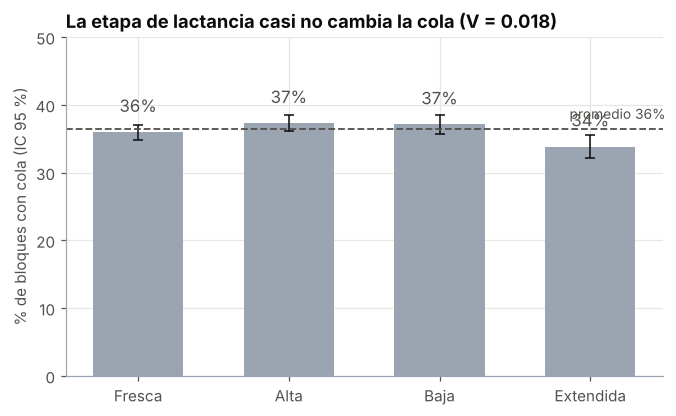

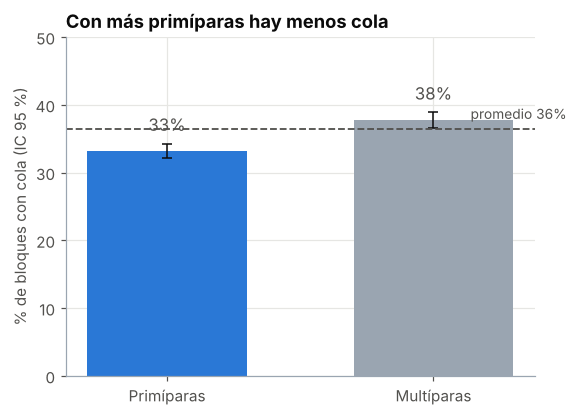

In [19]:
from scipy.stats import chi2_contingency

ETAPAS = ["pct_fresca", "pct_alta", "pct_baja", "pct_extendida"]
d2 = df[(df["total_ordenios"] > 0) & (df[ETAPAS].sum(axis=1) > 0)].copy()
d2["etapa_dominante"] = d2[ETAPAS].idxmax(axis=1).str.replace("pct_", "", regex=False)
d2["grupo_parto"] = np.where(d2["pct_primer_parto"] > 0.5, "Primíparas", "Multíparas")
promedio = d2["cola"].mean()

def chi2_tabla(col):
    t = pd.crosstab(d2[col], d2["cola"])
    chi2, p, gl, _ = chi2_contingency(t)
    v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
    return chi2, p, gl, v

chi_et = chi2_tabla("etapa_dominante")
chi_pp = chi2_tabla("grupo_parto")
print(f"Bloques con ordeños y etapa conocida: {len(d2):,} | % con cola: {promedio:.1%}")
print(f"Etapa dominante × cola: chi² = {chi_et[0]:.2f}, gl = {chi_et[2]}, p = {chi_et[1]:.2e}, V de Cramér = {chi_et[3]:.3f}")
print(f"Primíparas × cola:      chi² = {chi_pp[0]:.2f}, gl = {chi_pp[2]}, p = {chi_pp[1]:.2e}, V de Cramér = {chi_pp[3]:.3f}")

ic_et = ic_bootstrap_por_dia(d2, "etapa_dominante").loc[["fresca", "alta", "baja", "extendida"]]
ic_pp = ic_bootstrap_por_dia(d2, "grupo_parto").loc[["Primíparas", "Multíparas"]]

def barras(ax, r, colores, titulo):
    x = np.arange(len(r))
    ax.bar(x, r["pct"] * 100, color=colores, width=0.6)
    ax.errorbar(x, r["pct"] * 100, yerr=[(r["pct"] - r["ic_inf"]) * 100, (r["ic_sup"] - r["pct"]) * 100],
                fmt="none", ecolor="#0b0b0b", capsize=3, linewidth=1)
    for xi, v in zip(x, r["pct"]):
        ax.text(xi, v * 100 + 3, f"{v:.0%}", ha="center", color=TINTA2, fontsize=11)
    ax.axhline(promedio * 100, color=TINTA2, linestyle="--", linewidth=1.2)
    ax.text(len(r) - 0.5, promedio * 100 + 1, f"promedio {promedio:.0%}", ha="right", va="bottom", color=TINTA2, fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels([str(i).capitalize() for i in r.index])
    ax.set(ylim=(0, 50), ylabel="% de bloques con cola (IC 95 %)")
    ax.set_title(titulo)

fig, ax = plt.subplots(figsize=(7, 4))
barras(ax, ic_et, [GRIS] * 4, f"La etapa de lactancia casi no cambia la cola (V = {chi_et[3]:.3f})")
guardar(fig, "14_cola_por_etapa")

fig, ax = plt.subplots(figsize=(5.5, 4))
barras(ax, ic_pp, [AZUL, GRIS], "Con más primíparas hay menos cola")
guardar(fig, "15_primiparas")

## 7. Mensajes clave (para copiar a las diapositivas)

Los números se generan con los resultados de arriba. Antes de presentarlos, revisa que la interpretación siga siendo válida si cambian.

In [20]:
rh = por_hora["Reciente (test)"]
pico, valle = rh["pct"].idxmax(), rh["pct"].idxmin()
lr = tabla_modelos.loc["Regresión logística (umbral 0.2095)"]
sc = tabla_modelos.loc["Línea base: siempre cola"]
d_sc = boot["Regresión logística (umbral 0.2095)"] - boot["Línea base: siempre cola"]
peor, mejor = res.loc[res["escenario"].str.startswith("PEOR"), "prob_cola_%"].iloc[0], res.loc[res["escenario"].str.startswith("MEJOR"), "prob_cola_%"].iloc[0]
ant = res.set_index("escenario")["prob_cola_%"]

mensajes = [
    f"La cola es frecuente y creciente: {df.loc[df.periodo != 'Reciente (test)', 'cola'].mean():.0%} de los bloques en el histórico vs {reciente['cola'].mean():.0%} en jun–dic 2025.",
    f"Más vacas, más cola: +10 vacas activas ≈ +{pend * 10:.1f} pp de cola (IC {p_inf * 10:.1f}–{p_sup * 10:.1f} pp).",
    f"Hora con más cola: {pico}:00 ({rh.loc[pico, 'pct']:.0%}, IC {rh.loc[pico, 'ic_inf']:.0%}–{rh.loc[pico, 'ic_sup']:.0%}); con menos: {valle}:00 ({rh.loc[valle, 'pct']:.0%}).",
    f"En ventanas de 3 h, {resumen_ventanas[2]['% ventanas saturadas']:.0f} % están saturadas; una cola dura en mediana {ep['horas'].median():.1f} h y el {(ep['horas'] >= 2).mean():.0%} dura 2 h o más.",
    f"VMS 1 es el robot con más cola ({por_robot.loc[('Reciente (test)', 'VMS 1'), 'pct']:.0%}) y VMS 3 el que menos ({por_robot.loc[('Reciente (test)', 'VMS 3'), 'pct']:.0%}).",
    f"Modelo elegido (LR): F1 {lr['F1']:.3f} (IC {lr['F1 IC inf']:.3f}–{lr['F1 IC sup']:.3f}) vs 'siempre cola' {sc['F1']:.3f}; "
    f"la LR gana en {(d_sc > 0).mean():.0%} de los remuestreos por día. MCC {lr['MCC']:.2f} (siempre cola = 0).",
    f"Con el umbral 0.2095 la LR marca cola en {(prob >= UMBRAL).mean():.0%} de los bloques (real {y.mean():.0%}): conviene decirlo al presentar el F1.",
    f"Las probabilidades originales subestiman la cola (media {prob.mean():.0%} vs real {y.mean():.0%}) porque el hato cambió; recalibradas con validación: {test['prob_cal'].mean():.0%}.",
    f"Alerta temprana: si el bloque anterior tuvo cola, la probabilidad sube a {ant['El bloque anterior SÍ tuvo cola']:.0f} % (vs {ant['El bloque anterior NO tuvo cola']:.0f} % si no).",
    f"Escenarios extremos (solo variables anticipables): peor caso {peor:.0f} % vs mejor caso {mejor:.0f} %.",
]
for i, m in enumerate(mensajes, 1):
    print(f"{i}. {m}")

tabla_modelos.to_csv(FIG_DIR / "tabla_modelos_bootstrap.csv")
res.to_csv(FIG_DIR / "tabla_escenarios.csv", index=False)
coef.to_csv(FIG_DIR / "tabla_pesos_lr.csv", index=False)
print(f"\nFiguras y tablas guardadas en: {FIG_DIR}")

1. La cola es frecuente y creciente: 20% de los bloques en el histórico vs 58% en jun–dic 2025.
2. Más vacas, más cola: +10 vacas activas ≈ +5.3 pp de cola (IC 4.8–5.8 pp).
3. Hora con más cola: 18:00 (72%, IC 69%–75%); con menos: 4:00 (14%).
4. En ventanas de 3 h, 74 % están saturadas; una cola dura en mediana 1.0 h y el 29% dura 2 h o más.
5. VMS 1 es el robot con más cola (63%) y VMS 3 el que menos (53%).
6. Modelo elegido (LR): F1 0.791 (IC 0.782–0.799) vs 'siempre cola' 0.730; la LR gana en 100% de los remuestreos por día. MCC 0.42 (siempre cola = 0).
7. Con el umbral 0.2095 la LR marca cola en 78% de los bloques (real 58%): conviene decirlo al presentar el F1.
8. Las probabilidades originales subestiman la cola (media 33% vs real 58%) porque el hato cambió; recalibradas con validación: 48%.
9. Alerta temprana: si el bloque anterior tuvo cola, la probabilidad sube a 49 % (vs 46 % si no).
10. Escenarios extremos (solo variables anticipables): peor caso 54 % vs mejor caso 42 %.

Fig